# 🔁 ReAct Agents in LangGraph: Reason, Act, Observe, Repeat

## Learning Objectives
In this notebook, you will learn:
1. **The ReAct pattern** - Why interleaving reasoning and tool calls beats planning everything up front
2. **State and tools for an agent** - A message-list state and a live web-search tool bound to the LLM
3. **The single-shot baseline** - What an augmented LLM (`tools → END`) does with a multi-hop question
4. **The ReAct loop** - One edge (`tools → agent`) turns the augmented LLM into an agent that keeps going until it can answer
5. **Measuring the difference** - Scoring both agents with an LLM-as-a-judge

## Where this fits
Module 02 built an augmented LLM that calls one tool and stops (`03_augmented_llm_with_tools_langgraph.ipynb`), then closed the loop and made it robust (`04_tool_loop_errors_and_evaluation.ipynb`). This notebook treats that loop as an **agent architecture**: ReAct. It puts the one-shot and looping versions side by side on a question that needs several dependent searches. The next notebook, `02_tool_calling_vs_react.ipynb`, shows the older, text-based way of driving the same loop.

## Prerequisites
- LangGraph state, `ToolNode` and conditional edges — `03_augmented_llm_with_tools_langgraph.ipynb` (module 02)
- Dependencies installed with `uv sync` at the repository root
- `OPENAI_API_KEY` and `TAVILY_API_KEY` in the project-root `.env` (the agent searches the live web)

| Property | Value |
|---|---|
| Origin | Yao et al., *ReAct: Synergizing Reasoning and Acting in Language Models*, ICLR 2023 ([arXiv:2210.03629](https://arxiv.org/abs/2210.03629)) |

---
## 📦 Step 1: Environment Setup

The setup cell loads the API keys; the next cell creates the LLM that will act as the agent's reasoning engine.

In [1]:
# ============================================================================
# ENVIRONMENT SETUP: Load API keys and suppress warnings
# ============================================================================
import warnings

from dotenv import find_dotenv, load_dotenv

warnings.filterwarnings("ignore")

# Reads OPENAI_API_KEY and TAVILY_API_KEY from the project-root .env
load_dotenv(find_dotenv(usecwd=True))

print("✅ Environment ready")

✅ Environment ready


In [2]:
# ============================================================================
# LLM INITIALIZATION: The agent's reasoning engine
# ============================================================================
from aied_helpers import get_openai_llm

llm = get_openai_llm(model="gpt-4o-mini")

print(f"✅ LLM initialized: {llm.model_name}")

✅ LLM initialized: gpt-4o-mini


---
## 🧠 Part 1: What ReAct Is

The **ReAct** architecture is a design pattern where an agent interleaves reasoning steps with actions. Instead of planning all its steps upfront, the agent generates a thought about its immediate next step, takes an action (like calling a tool), observes the result, and then uses that new information to generate its next thought and action. This creates a dynamic and adaptive loop.

### High-level Workflow

1.  **Receive Goal:** The agent is given a complex task.
2.  **Think (Reason):** The agent generates an internal thought, such as: *"To answer this, I first need to find piece of information X."*
3.  **Act:** Based on its thought, the agent executes an action, typically calling a tool (e.g., `search_api('X')`).
4.  **Observe:** The agent receives the result from the tool.
5.  **Repeat:** The agent incorporates the observation into its context and returns to step 2, generating a new thought (e.g., *"Okay, now that I have X, I need to use it to find Y."*). This loop continues until the overall goal is satisfied.

### Augmented LLM vs. AI Agent

```
Augmented LLM:  User → LLM → Tool → END            (raw tool output goes to the user)
ReAct agent:    User → LLM → Tool → LLM → … → END  (the LLM reads every result and decides again)
```

| Feature | Description |
|---------|-------------|
| **Autonomy** | Makes decisions without human intervention |
| **Reasoning** | Analyzes context to decide next action |
| **Tool Use** | Calls external tools when needed |
| **Feedback Loop** | Processes results and can take further actions |
| **Goal-Oriented** | Works toward completing user's objective |

### When to Use / Applications
*   **Multi-hop Question Answering:** When answering a question requires finding several pieces of information in sequence (e.g., "Who is the CEO of the company that makes the iPhone?").
*   **Web Navigation & Research:** An agent can search for a starting point, read the results, and then decide on a new search query based on what it learned.
*   **Interactive Workflows:** Any task where the environment is dynamic and the full path to a solution cannot be known in advance.

### Strengths & Weaknesses
*   **Strengths:**
    *   **Adaptive & Dynamic:** Can adjust its plan on the fly based on new information.
    *   **Handles Complexity:** Excels at problems that require chaining multiple dependent steps.
*   **Weaknesses:**
    *   **Higher Latency & Cost:** Involves multiple sequential LLM calls, making it slower and more expensive than single-shot approaches.
    *   **Risk of Loops:** A poorly guided agent can get stuck in repetitive, unproductive loops of thought and action.

> **Key Insight**: In a tool-calling model, the "thought" is the model's decision to emit a `tool_call` (and which arguments to use); the "observation" is the `ToolMessage` that comes back. The graph below makes that loop explicit.

---
## 🧩 Part 2: State and Tools

For an agent with a feedback loop, the message history is the whole story of the run:

```
1. HumanMessage     - User's original query
2. AIMessage        - LLM's response (with tool_calls)
3. ToolMessage      - Results from tool execution
4. AIMessage        - LLM processes tool results (may call more tools)
5. ToolMessage      - More tool results (if needed)
6. AIMessage        - Final human-readable response
```

The `add_messages` reducer appends every new message to that list, so on each turn the LLM sees what the user asked, which tools it called, and what came back.

In [3]:
# ============================================================================
# DEFINING AGENT STATE: A list of messages that only ever grows
# ============================================================================
from typing import Annotated

from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict


class AgentState(TypedDict):
    """State for both agents in this notebook.

    add_messages appends new messages instead of overwriting the list, which is
    what lets the LLM see earlier tool results on its next turn.
    """

    messages: Annotated[list[AnyMessage], add_messages]


print(f"✅ State defined with keys: {list(AgentState.__annotations__)}")

✅ State defined with keys: ['messages']


### 2.1 🔍 A Live Web-Search Tool

The tool wraps Tavily, a search API built for LLM agents. It returns only the title, URL and a trimmed snippet of the top three hits — enough for the model to reason over without flooding its context. The docstring is what the model reads when it decides whether to search.

In [4]:
# ============================================================================
# CREATE THE TOOL AND AUGMENT THE LLM
# ============================================================================
from langchain_core.tools import tool
from langchain_tavily import TavilySearch

tavily = TavilySearch(max_results=3)


@tool
def search_web(query: str) -> list[dict]:
    """Search the web for current information, news or facts you do not know.

    Use this tool when the question needs real-time information or facts beyond
    your training data. Search for one fact at a time.

    Args:
        query: The search query to look up.
    """
    print(f"  [TOOL CALL] search_web({query!r})")
    response = tavily.invoke({"query": query})
    # Keep the observation small: title, URL and a trimmed snippet per hit
    return [
        {"title": r["title"], "url": r["url"], "content": r["content"][:700]}
        for r in response["results"]
    ]


tools = [search_web]

# bind_tools() gives the LLM the tool schemas, so it can reply with tool_calls
llm_with_tools = llm.bind_tools(tools)

print(f"✅ Agent equipped with {len(tools)} tool(s): {[t.name for t in tools]}")

✅ Agent equipped with 1 tool(s): ['search_web']


In [5]:
# ============================================================================
# TEST: The augmented LLM decides to call the tool
# ============================================================================
response = llm_with_tools.invoke("What is the latest news on Nvidia?")

if response.tool_calls:
    print("✅ The LLM decided to call a tool:")
    for tc in response.tool_calls:
        print(f"   {tc['name']}({tc['args']})")
else:
    print(f"The LLM answered directly: {response.content}")

✅ The LLM decided to call a tool:
   search_web({'query': 'latest news on Nvidia'})


Notice that the LLM did not run anything: it returned a *request* to call `search_web`. Executing that request, and deciding what happens with the result, is the graph's job.

---
## 🎯 Part 3: The Single-Shot Baseline

To understand why ReAct is so powerful, we must first see what happens without it. We will build a "basic" agent that can use tools, but only once. It will analyze a user's query, make a single tool call, and then the workflow ends: `agent → tools → END`. There is no loop, so the tool's raw output is the last word.

✅ Basic single-shot agent compiled


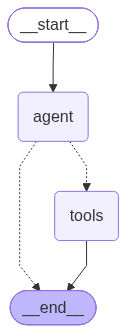

In [6]:
# ============================================================================
# BUILD THE BASELINE: agent → tools → END (no loop)
# ============================================================================
from IPython.display import Image, display
from langgraph.graph import END, START, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition


def basic_agent_node(state: AgentState):
    """Call the tool-augmented LLM once."""
    print("--- BASIC AGENT: Thinking... ---")
    system_prompt = (
        "You are a helpful assistant with a web search tool. "
        "Answer the user's question based on the tool's results. "
        "You get exactly one tool call."
    )
    response = llm_with_tools.invoke([("system", system_prompt)] + state["messages"])
    return {"messages": [response]}


basic_builder = StateGraph(AgentState)
basic_builder.add_node("agent", basic_agent_node)
basic_builder.add_node("tools", ToolNode(tools))

basic_builder.add_edge(START, "agent")
# tools_condition returns "tools" when the last AIMessage has tool_calls, else END
basic_builder.add_conditional_edges("agent", tools_condition, ["tools", END])
# After the tools run, the workflow MUST end: no second look at the results
basic_builder.add_edge("tools", END)

basic_agent = basic_builder.compile()


def show_graph(graph):
    """Render a compiled graph as PNG, falling back to Mermaid text when offline."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as exc:  # mermaid.ink not reachable
        print(f"(PNG render unavailable: {exc.__class__.__name__})")
        print(graph.get_graph().draw_mermaid())


print("✅ Basic single-shot agent compiled")
show_graph(basic_agent)

### 3.1 🧪 A Question That Needs Several Dependent Searches

Answering it means: find the company behind *Dune*, then its CEO, then that company's latest film, then that film's budget. Each step depends on the one before.

In [7]:
# ============================================================================
# TEST: The baseline on a multi-hop question
# ============================================================================
multi_step_query = (
    "Who is the current CEO of the company that created the sci-fi movie 'Dune', "
    "and what was the budget for that company's most recent film?"
)

print(f"❓ {multi_step_query}\n")
basic_output = basic_agent.invoke({"messages": [("user", multi_step_query)]})

last = basic_output["messages"][-1]
print(f"\n📤 Last message type: {last.__class__.__name__}")
print(f"📤 What the user gets back (first 600 chars):\n{str(last.content)[:600]}")

❓ Who is the current CEO of the company that created the sci-fi movie 'Dune', and what was the budget for that company's most recent film?

--- BASIC AGENT: Thinking... ---
  [TOOL CALL] search_web('current CEO of Legendary Entertainment 2023')

📤 Last message type: ToolMessage
📤 What the user gets back (first 600 chars):
[{"title": "Joshua Grode named CEO of Legendary Entertainment | News | Screen", "url": "https://www.screendaily.com/news/-joshua-grode-named-ceo-of-legendary-entertainment/5124748.article", "content": "According to Legendary, Grode has been integral in transforming the company’s financial and operating plan over the past 12 months. Grode identified new executive management including the recently appointed CFO, Ron Hohauser, and head of Human Resources, Haylen van Koppen. The appointment of Grode to CEO follows a planned departure of former CEO Thomas Tull, who left the company last January. [.


The basic agent fails in a telling way. It gets exactly one round of tool calls — sometimes one search for the whole question, sometimes a few searches fired in parallel from what it already guesses — and then the graph ends. The "answer" the user receives is the raw `ToolMessage`: search snippets, not a sentence. Even if the snippets happened to contain every fact, nothing in this graph reads them, and no search can build on another. The problem needs a chain:
1.  Find the company that made 'Dune' (Legendary Entertainment).
2.  Find the CEO of that company.
3.  Find that company's most recent film, then that film's budget.

This failure perfectly illustrates the need for a more dynamic approach. The agent needs a way to **react** to the information it finds in one step to inform the next.

---
## 🔁 Part 4: The ReAct Loop

The core difference is one edge. After the tools run, their results go **back to the agent** instead of to `END`. The agent then either calls more tools (another think → act → observe round) or answers, and `tools_condition` ends the run when there are no more tool calls.

```
START → agent ──tools_condition──► END      (no tool call: final answer)
          ▲             │
          │             ▼
          └───────── tools                  (tool results go back to the agent)
```

### Key Components

| Component | Purpose |
|-----------|---------|
| **agent** | Node that calls the augmented LLM on the whole message history |
| **tools** (`ToolNode`) | Executes the requested tool calls and appends `ToolMessage`s |
| **tools_condition** | Routes to `tools` if the last AIMessage has tool calls, else to `END` |
| **`tools → agent`** | The feedback loop: every observation is read before the next decision |

✅ ReAct agent compiled with a reasoning loop


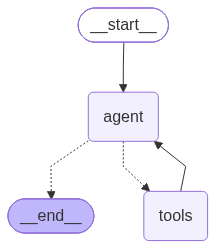

In [8]:
# ============================================================================
# BUILD THE REACT AGENT: agent ⇄ tools
# ============================================================================
REACT_SYSTEM_PROMPT = (
    "You are a research assistant with a web search tool. Break multi-part questions "
    "into single facts, search for one fact at a time, and use each result to decide "
    "your next search. Answer only when you have every part, citing what you found."
)


def react_agent_node(state: AgentState):
    """Call the tool-augmented LLM on the full history, including earlier tool results."""
    print("--- REACT AGENT: Thinking... ---")
    response = llm_with_tools.invoke([("system", REACT_SYSTEM_PROMPT)] + state["messages"])
    return {"messages": [response]}


react_builder = StateGraph(AgentState)
react_builder.add_node("agent", react_agent_node)
react_builder.add_node("tools", ToolNode(tools))

react_builder.add_edge(START, "agent")
react_builder.add_conditional_edges("agent", tools_condition, ["tools", END])
# THE KEY DIFFERENCE: tool results go back to the agent, not to END
react_builder.add_edge("tools", "agent")

react_agent = react_builder.compile()

print("✅ ReAct agent compiled with a reasoning loop")
show_graph(react_agent)

### 4.1 💬 A Question That Needs No Tools

The loop costs nothing when it is not needed: the agent answers in one pass, `START → agent → END`.

In [9]:
# ============================================================================
# TEST 1: No tool needed
# ============================================================================
for event in react_agent.stream({"messages": [("user", "Explain AI in 2 bullets")]},
                                stream_mode="values"):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Explain AI in 2 bullets
--- REACT AGENT: Thinking... ---
================================== Ai Message ==================================

1. **Definition**: Artificial Intelligence (AI) refers to the simulation of human intelligence in machines that are programmed to think, learn, and perform tasks that typically require human cognitive functions, such as problem-solving, understanding natural language, and recognizing patterns.

2. **Applications**: AI is utilized across various fields, including healthcare (for diagnostics and personalized medicine), finance (for fraud detection and algorithmic trading), autonomous vehicles, customer service (through chatbots), and many more, enhancing efficiency and decision-making processes.


### 4.2 🔍 The Multi-Hop Question Again

Stream the run and watch the loop: each `AIMessage` with a tool call is a *thought + action*, each `ToolMessage` an *observation*, and the next search is chosen using what the previous one found.

In [10]:
# ============================================================================
# TEST 2: The same multi-hop question, now with the loop
# ============================================================================
react_output = None
for event in react_agent.stream({"messages": [("user", multi_step_query)]},
                                stream_mode="values"):
    react_output = event
    event["messages"][-1].pretty_print()

searches = [tc["args"]["query"] for m in react_output["messages"]
            for tc in getattr(m, "tool_calls", [])]
print(f"\n🔎 The agent ran {len(searches)} searches:")
for q in searches:
    print(f"   - {q}")

================================ Human Message =================================

Who is the current CEO of the company that created the sci-fi movie 'Dune', and what was the budget for that company's most recent film?
--- REACT AGENT: Thinking... ---
================================== Ai Message ==================================
Tool Calls:
  search_web (call_N1KMCTQrV2xXUOfpPd7XQ2Iw)
 Call ID: call_N1KMCTQrV2xXUOfpPd7XQ2Iw
  Args:
    query: current CEO of Legendary Entertainment 2023
  [TOOL CALL] search_web('current CEO of Legendary Entertainment 2023')
================================= Tool Message =================================
Name: search_web

[{"title": "Joshua Grode named CEO of Legendary Entertainment | News | Screen", "url": "https://www.screendaily.com/news/-joshua-grode-named-ceo-of-legendary-entertainment/5124748.article", "content": "According to Legendary, Grode has been integral in transforming the company’s financial and operating plan over the past 12 months. Gr

The execution trace shows a completely different and far more intelligent process. Each `AIMessage` with a tool call is a thought turned into an action; each `ToolMessage` is an observation. Look at the later searches: they name things (a film title, a person) that only appeared in *earlier results* — the loop is what let the agent use them. The final message is an `AIMessage` written *from* the observations, not the observations themselves.

---
## 📏 Part 5: Measuring the Difference with an LLM-as-a-Judge

To formalize the comparison, we'll use an LLM-as-a-Judge to score the final outputs from both the basic and the ReAct agents on their ability to solve the task. `with_structured_output` makes the judge return a Pydantic object instead of prose, so the scores are machine-readable.

In [11]:
# ============================================================================
# LLM-AS-A-JUDGE: Score both runs on the same rubric
# ============================================================================
from pydantic import BaseModel, Field


class TaskEvaluation(BaseModel):
    """Schema for evaluating an agent's ability to complete a task."""

    task_completion_score: int = Field(description="Score 1-10 on whether the agent successfully completed all parts of the user's request.")
    reasoning_quality_score: int = Field(description="Score 1-10 on the logical flow and reasoning process demonstrated by the agent.")
    justification: str = Field(description="A brief justification for the scores.")


judge_llm = llm.with_structured_output(TaskEvaluation)


def evaluate_agent_output(query: str, agent_output: dict) -> TaskEvaluation:
    """Show the judge the whole trace (truncated per message) and ask for scores."""
    trace = "\n".join(f"{m.type}: {str(m.content)[:1500]}" for m in agent_output["messages"])
    prompt = f"""You are an expert judge of AI agents. Evaluate the following agent's performance on the given task on a scale of 1-10. A score of 10 means the task was completed perfectly. A score of 1 means complete failure. The user only sees the LAST message of the trace.

**User's Task:**
{query}

**Full Agent Conversation Trace:**
```
{trace}
```
"""
    return judge_llm.invoke(prompt)


for label, output in [("Basic (single-shot)", basic_output), ("ReAct", react_output)]:
    ev = evaluate_agent_output(multi_step_query, output)
    print(f"🧑‍⚖️ {label}: completion={ev.task_completion_score}/10, "
          f"reasoning={ev.reasoning_quality_score}/10")
    print(f"   {ev.justification}\n")

🧑‍⚖️ Basic (single-shot): completion=7/10, reasoning=6/10
   The agent successfully identified the current CEO of Legendary Entertainment, which is the company that created 'Dune'. However, it did not provide information about the budget for the company's most recent film, which is a crucial part of the user's request. The reasoning quality is decent, as it provided relevant information about the CEO, but it lacked completeness in addressing both parts of the user's question.

🧑‍⚖️ ReAct: completion=10/10, reasoning=9/10
   The agent successfully identified the current CEO of Legendary Entertainment as Joshua Grode and provided the budget for the company's most recent film, 'A Minecraft Movie', as $150 million. The information is accurate and directly answers the user's query. The reasoning quality is slightly lower due to the lack of explicit mention of the release date of 'A Minecraft Movie', which could enhance the context.



The judge should score the basic agent low on completion — the user received raw search results — and the ReAct agent much higher, because its iterative process gathered each fact in turn and synthesized them. Two caveats worth keeping: the judge here is the same model as the agent (use an independent, stronger judge in practice), and live search results change, so the exact scores vary from run to run.

---
## 📝 Summary

In this notebook, we learned:

### 1. The ReAct Pattern
- Reason → act → observe → repeat: each tool result informs the next decision
- Worth its extra latency and cost on multi-hop problems whose path cannot be planned up front

### 2. State and Tools
- A message list with `add_messages` is the agent's memory for the run
- `bind_tools()` lets the LLM *request* tool calls; the graph executes them

### 3. The Single-Shot Baseline
- `tools → END` returns raw tool output and gets one shot at the problem, so it fails multi-hop questions

### 4. The ReAct Loop
- One edge, `tools → agent`, closes the loop; `tools_condition` ends it when the model stops calling tools
- The same graph answers simple questions in a single pass

### 5. Measuring the Difference
- An LLM-as-a-judge with a structured schema turns "looks better" into comparable scores

### Next Steps
- **`02_tool_calling_vs_react.ipynb`**: the same loop driven by native tool calls vs. by parsing `Thought / Action / Observation` text